# Modularity on the Karate Club Graph
DSC212 – Graph Theory Module

In this notebook I implement spectral modularity partitioning from scratch on
Zachary's Karate Club network (34 members, 78 edges). I split the network
recursively using the leading eigenvector of the modularity matrix (Newman, 2006),
draw the graph after every split, and track four node metrics (degree,
betweenness, closeness, clustering) across the splits.

Reference: M. E. J. Newman, "Modularity and community structure in networks,"
PNAS 103(23):8577–8582, 2006.

Requirements: numpy, networkx, matplotlib. The last cell (optional video)
also needs imageio-ffmpeg.

In [47]:
import ipykernel
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt


G = nx.karate_club_graph()
m = G.number_of_edges()
print(f"Members: {G.number_of_nodes()}, edges: {G.number_of_edges()}")


Members: 34, edges: 78


## 1. The modularity matrix
The modularity matrix is B = A − kkᵀ/2m, where A is the adjacency matrix and k is
the degree vector. Entry B[i, j] is the actual number of edges between i and j
(0 or 1) minus the number expected if the edges were rewired at random while keeping
every degree fixed. I build it with `np.outer`. As a check, every row of B should sum
to zero.

In [48]:
nodes = sorted(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)

P = np.outer(k, k) / (2 * m)
B = A - P

print("Matrix shape:", B.shape)
print(f"B[0, 1] = {B[0, 1]:.4f}")
print("Do all rows sum to zero?", np.allclose(B.sum(axis=1), 0))

Matrix shape: (34, 34)
B[0, 1] = 0.0769
Do all rows sum to zero? True


## 2. Scoring a partition
For any partition into groups, the modularity is the sum of all entries of B that sit
inside a group, divided by 2m. For two groups this is the same as the handout's
Q = sᵀBs / 4m. I wrote it for any number of groups because the recursion produces more
than two.

In [49]:
def modularity(partition):
    total = 0.0

    for group in partition:
        # Q = (sum of B[i, j] over all pairs inside the same group) / (2m)
        within_group = B[np.ix_(group, group)]
        total += within_group.sum()

    return total / (2 * m)


# Start with everyone in a single group.
one_group = [nodes]

# Use the recorded club factions as an example partition.
mr_hi = [node for node in nodes if G.nodes[node]["club"] == "Mr. Hi"]
officer = [node for node in nodes if G.nodes[node]["club"] == "Officer"]
recorded_split = [mr_hi, officer]

print(f"One group:       Q = {modularity(one_group):.4f}")
print(f"Recorded split:  Q = {modularity(recorded_split):.4f}")

One group:       Q = -0.0000
Recorded split:  Q = 0.3582


## 3. First split with the leading eigenvector
B is real and symmetric, so I use `np.linalg.eigh`, which returns eigenvalues in
increasing order. The last one is the largest, and its eigenvector is the relaxed
solution from Rayleigh–Ritz. Nodes with a positive entry go to group A and the rest
to group B.

The leading eigenvalue is about 4.98 and the split gives 16 and 18 nodes, with
Q ≈ 0.3715. Compared with the real factions, only node 8 ends up on the wrong side.

In [50]:
eigenvalues, eigenvectors = np.linalg.eigh(B)

leading_value = eigenvalues[-1]
leading_vector = eigenvectors[:, -1]

# Put positive entries in one group and the rest in the other.
group_a = []
group_b = []

for node, value in zip(nodes, leading_vector):
    if value > 0:
        group_a.append(node)
    else:
        group_b.append(node)

first_split = [group_a, group_b]
gain = modularity(first_split) - modularity(one_group)

print(f"Largest eigenvalue: {leading_value:.4f}")
print("Group A:", group_a)
print("Group B:", group_b)
print(f"Modularity gain: {gain:.4f}")

Largest eigenvalue: 4.9771
Group A: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Group B: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Modularity gain: 0.3715


## 4. Splitting a group inside the recursion
The handout says to use the block B(C) of B restricted to the group C. The gain
from splitting C by a vector s is the new score minus the score C already had:

ΔQ = (1/4m) [ sᵀ B(C) s − 1ᵀ B(C) 1 ]

For the whole graph the second term is zero, because every row of B sums to zero.
For a subgroup the row sums of B(C) are not zero, so the second term does not vanish
and the plain block gives the wrong gain.

Newman (2006) handles this with the generalized matrix

H = B(C) − diag(row sums of B(C)).

Since every sᵢ² = 1, sᵀHs equals sᵀB(C)s − 1ᵀB(C)1, which is exactly the true
gain. So I use H instead of the plain block. For the first split H and B are
identical. I confirm in the next cell that the formula agrees with a full
before-and-after score.

I also reject a split if its real gain is not positive. A positive eigenvalue does not
guarantee this, because rounding the eigenvector to ±1 can lower Q.

In [51]:
TOL = 1e-10  # Ignore tiny differences caused by floating-point rounding.


def propose_split(group):
    """Return two candidate children, the leading eigenvalue, and the gain."""
    R = B[np.ix_(group, group)]
    H = R - np.diag(R.sum(axis=1))

    eigenvalues, eigenvectors = np.linalg.eigh(H)
    leading_value = eigenvalues[-1]

    if leading_value <= TOL:
        return None, leading_value, None

    leading_vector = eigenvectors[:, -1]
    signs = np.where(leading_vector > 0, 1, -1)

    left = [node for node, sign in zip(group, signs) if sign == 1]
    right = [node for node, sign in zip(group, signs) if sign == -1]

    if not left or not right:
        return None, leading_value, None

    gain = float((signs @ H @ signs) / (4 * m))
    return [left, right], leading_value, gain

## 5. Recursive bisection
`split_recursively` tries to split a group. If it finds a split with positive gain, it
records the new partition in `history` and then recurses on both halves. A group stays
whole if its leading eigenvalue is ≤ 0 or its best split has non-positive gain.

Every accepted split is checked in two ways: the gain from the formula must equal the
difference between the full Q scores, and every Q must match
`nx.community.modularity`.

Result: three accepted splits, final Q ≈ 0.393, with four communities of sizes
7, 9, 12 and 6. The splits and gains were:
- step 1: 34 → 16 + 18 (gain 0.3715)
- step 2: 16 → 7 + 9 (gain 0.0012)
- step 3: 18 → 12 + 6 (gain 0.0207)

The 9-node group had a positive eigenvalue, but its candidate split had a negative gain
(−0.0158), so it was rejected.

In [52]:
history = [one_group]


def split_recursively(group):
    """Try splitting one group, then visit its children if accepted."""
    children, leading_value, gain = propose_split(group)

    if children is None:
        print(f"Keep group of size {len(group)} (λ = {leading_value:.6f})")
        return

    before = history[-1]
    after = [part for part in before if part != group] + children

    # Check the quadratic formula against a full before-and-after score.
    direct_gain = modularity(after) - modularity(before)
    assert np.isclose(gain, direct_gain, atol=TOL, rtol=0)

    if gain <= TOL:
        print(f"Keep group of size {len(group)} (candidate gain = {gain:.6f})")
        return

    history.append(after)
    print(f"Step {len(history) - 1}: split {len(group)} into "
          f"{len(children[0])} and {len(children[1])}, gain = {gain:.6f}")

    for child in children:
        split_recursively(child)


split_recursively(nodes)

print("\nPartition scores")
for step, partition in enumerate(history):
    # Verify that every node appears exactly once.
    assert sorted(node for group in partition for node in group) == nodes

    score = modularity(partition)
    reference = nx.community.modularity(
        G, [set(group) for group in partition], weight=None
    )
    assert np.isclose(score, reference, atol=TOL, rtol=0)

    if step > 0:
        assert score > modularity(history[step - 1]) + TOL

    print(f"Step {step}: sizes {[len(group) for group in partition]}, Q = {score:.6f}")

if len(history) > 1:
    assert {frozenset(group) for group in history[1]} == {
        frozenset(group) for group in first_split
    }

print("\nFinal communities")
for number, group in enumerate(history[-1], start=1):
    print(f"Community {number}: {group}")

Step 1: split 34 into 16 and 18, gain = 0.371466
Step 2: split 16 into 7 and 9, gain = 0.001233
Keep group of size 7 (λ = -0.000000)
Keep group of size 9 (candidate gain = -0.015779)
Step 3: split 18 into 12 and 6, gain = 0.020710
Keep group of size 12 (λ = 0.000000)
Keep group of size 6 (λ = 0.000000)

Partition scores
Step 0: sizes [34], Q = -0.000000
Step 1: sizes [16, 18], Q = 0.371466
Step 2: sizes [18, 7, 9], Q = 0.372699
Step 3: sizes [7, 9, 12, 6], Q = 0.393409

Final communities
Community 1: [0, 4, 5, 6, 10, 11, 16]
Community 2: [1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 3: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
Community 4: [23, 24, 25, 27, 28, 31]


## 6. Visualizing each step
Node positions are computed once with a fixed seed so nodes do not move between
figures. A community keeps its color until it splits. Solid edges join nodes in the
same community and dashed edges cross communities. Each title shows the step number,
the number of communities, and Q.

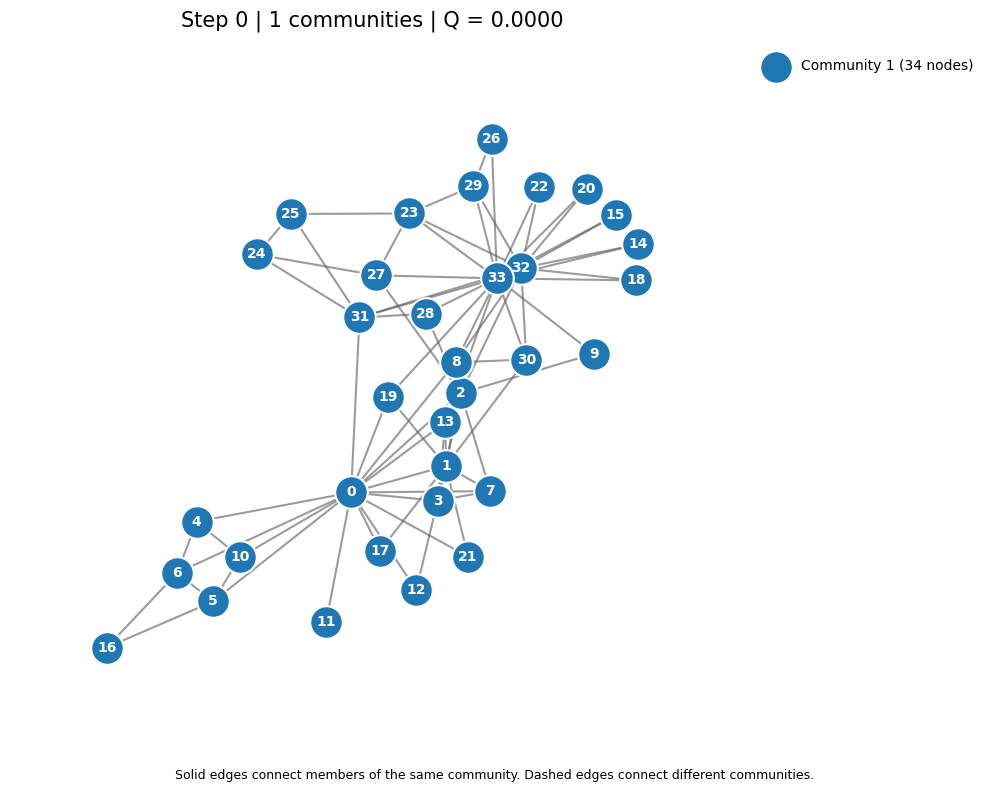

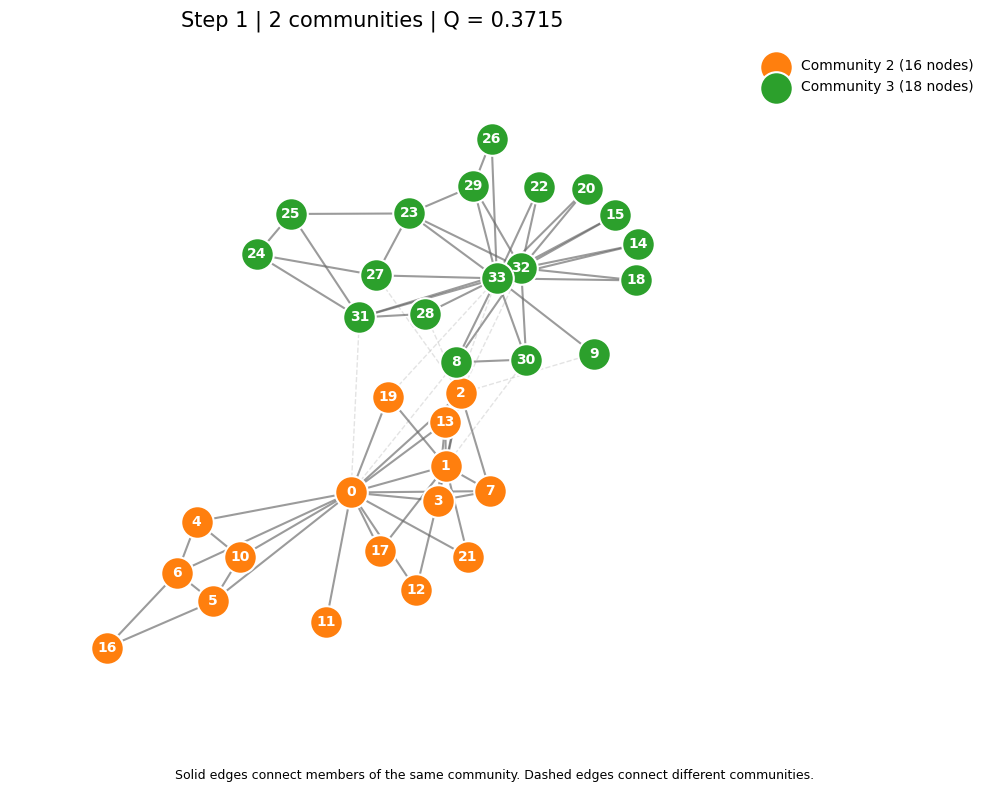

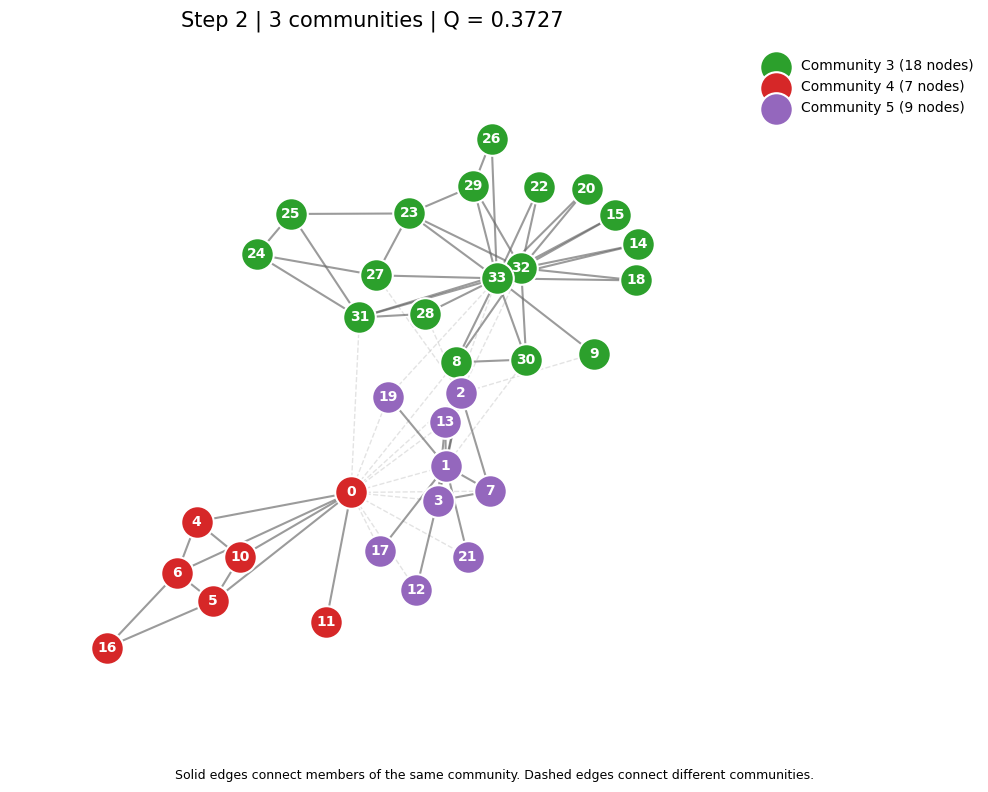

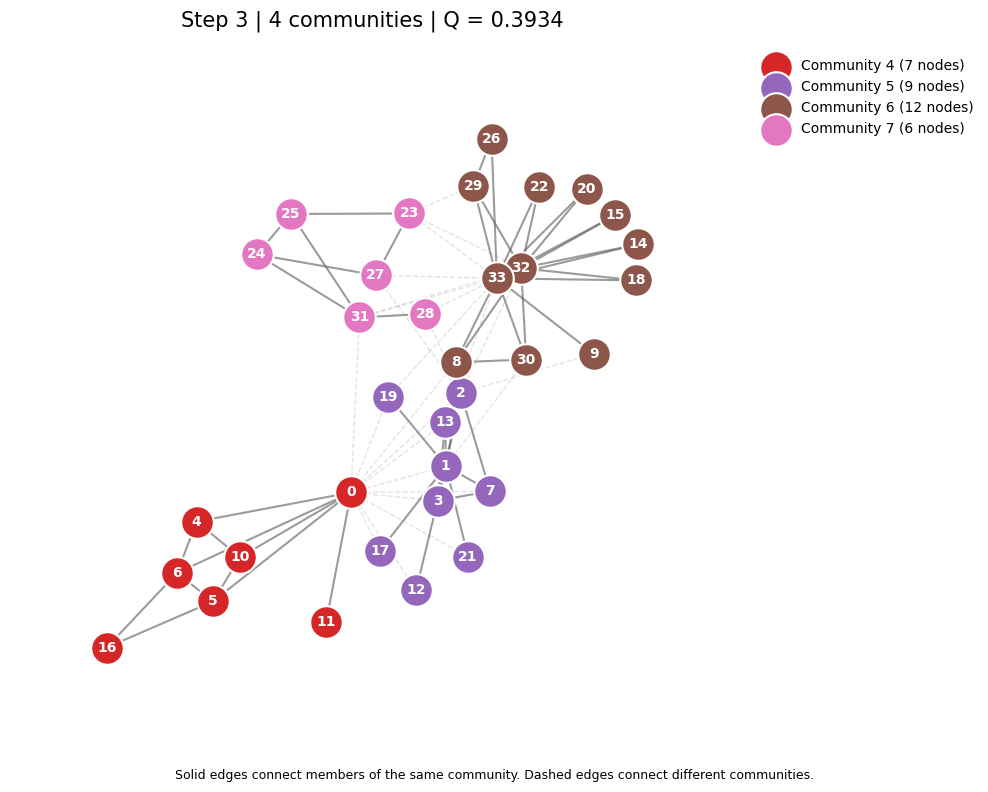

In [53]:
# Calculate positions once so nodes stay in place across all figures.
positions = nx.spring_layout(
    G,
    seed=212,
    weight=None,
    k=0.5,
    iterations=200,
)

palette = plt.get_cmap("tab10").colors
community_colors = {}
community_ids = {}

for step, partition in enumerate(history):
    fig, ax = plt.subplots(figsize=(10, 8))

    # Record which community contains each node at this step.
    membership = {}

    for group_number, group in enumerate(partition):
        for node in group:
            membership[node] = group_number

    inside_edges = []
    between_edges = []

    for u, v in G.edges():
        if membership[u] == membership[v]:
            inside_edges.append((u, v))
        else:
            between_edges.append((u, v))

    # Draw edges first so nodes and labels appear on top.
    nx.draw_networkx_edges(
        G,
        positions,
        edgelist=between_edges,
        edge_color="#b0b0b0",
        style="dashed",
        width=1,
        alpha=0.35,
        ax=ax,
    )

    nx.draw_networkx_edges(
        G,
        positions,
        edgelist=inside_edges,
        edge_color="#666666",
        width=1.5,
        alpha=0.65,
        ax=ax,
    )

    # A community keeps its color and ID until it splits.
    for group in partition:
        key = frozenset(group)

        if key not in community_colors:
            index = len(community_colors)
            community_colors[key] = palette[index % len(palette)]
            community_ids[key] = index + 1

        nx.draw_networkx_nodes(
            G,
            positions,
            nodelist=group,
            node_color=[community_colors[key]],
            node_size=550,
            edgecolors="white",
            linewidths=1.5,
            label=f"Community {community_ids[key]} ({len(group)} nodes)",
            ax=ax,
        )

    nx.draw_networkx_labels(
        G,
        positions,
        font_size=10,
        font_color="white",
        font_weight="bold",
        ax=ax,
    )

    score = modularity(partition)

    # Display tiny rounding errors around zero as zero.
    if abs(score) < TOL:
        score = 0.0

    ax.set_title(
        f"Step {step} | {len(partition)} communities | Q = {score:.4f}",
        fontsize=15,
        pad=15,
    )

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        frameon=False,
    )

    fig.text(
        0.5,
        0.02,
        "Solid edges connect members of the same community. "
        "Dashed edges connect different communities.",
        ha="center",
        fontsize=9,
    )

    ax.margins(0.12)
    ax.set_axis_off()
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

## 7. Node metrics after each split
After every step I compute the four networkx metrics.

**Choice I made:** the handout does not say whether the metrics should be computed
on the whole graph or inside each community. I compute them on each community's own
subgraph. Step 0 is the whole graph. This shows how a node looks from inside its
community.

**Consequence:** the values at different steps are not directly comparable. Every
split changes the number of nodes, and networkx normalizes each metric by that number.
A drop in a node's centrality can be due to the smaller subgraph and not to the node
becoming less important. A subgraph can also be disconnected, and networkx's closeness
handles that with a scaling factor.

## 8. How the metrics change across steps
One figure per metric. Each line is one node, and the nodes are split into two panels of 17 so the legends stay readable. The x-axis is the split step, and the y-axis is the metric value.

In [54]:
measures = {
    "Degree centrality": nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality": nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

metrics = {}

for step, partition in enumerate(history):
    metrics[step] = {name: {} for name in measures}

    for group in partition:
        subgraph = G.subgraph(group)

        for name, measure in measures.items():
            values = measure(subgraph)
            if name == "Degree centrality" and len(group) == 1:
                # Convention for a group with nobody else to connect to.
                values = {group[0]: 0.0}
            metrics[step][name].update(values)

    assert all(set(values) == set(nodes) for values in metrics[step].values())

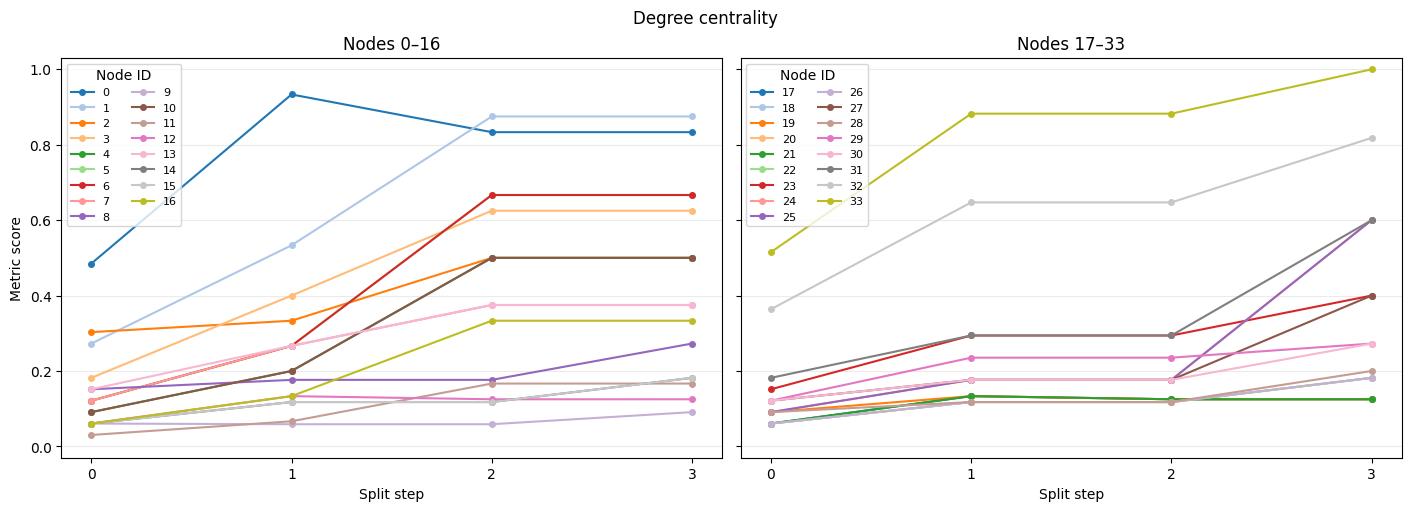

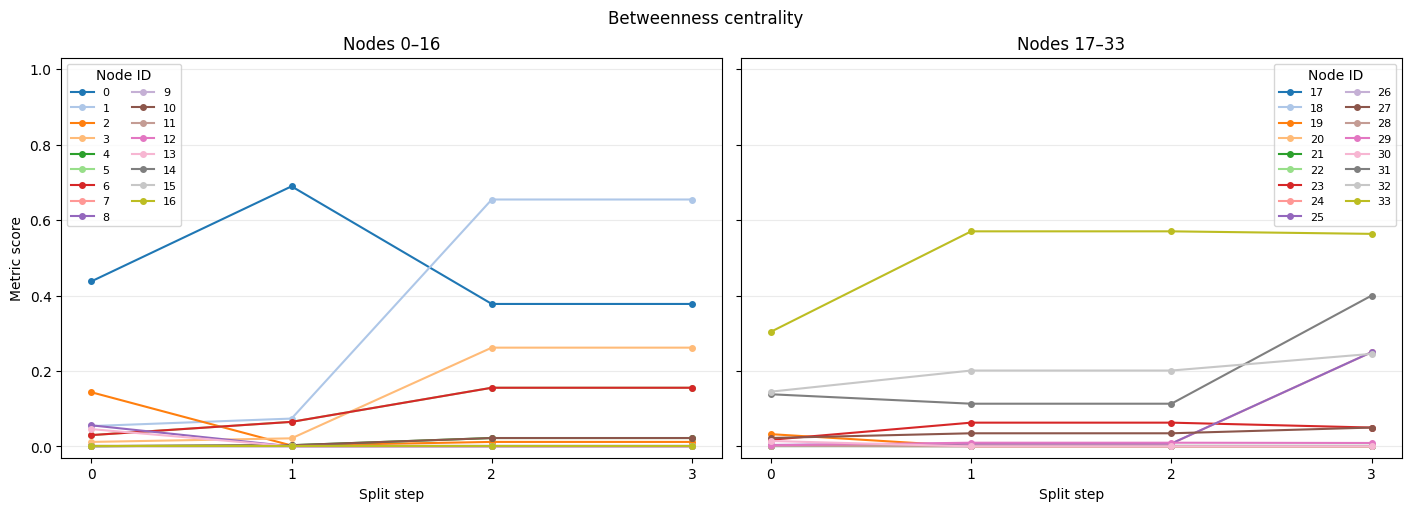

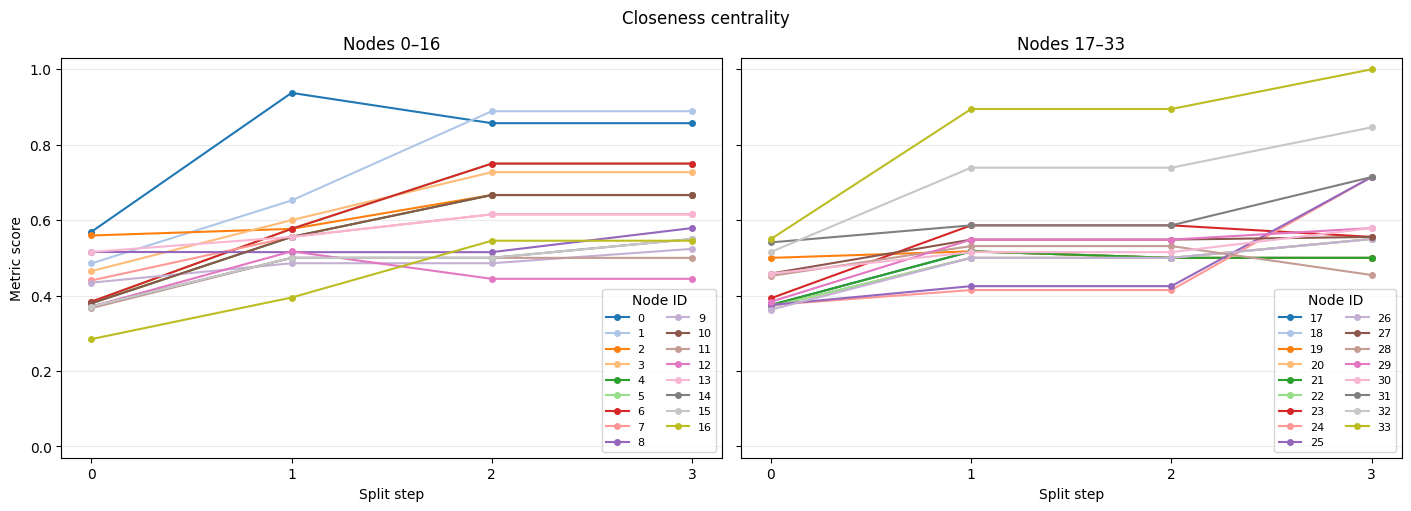

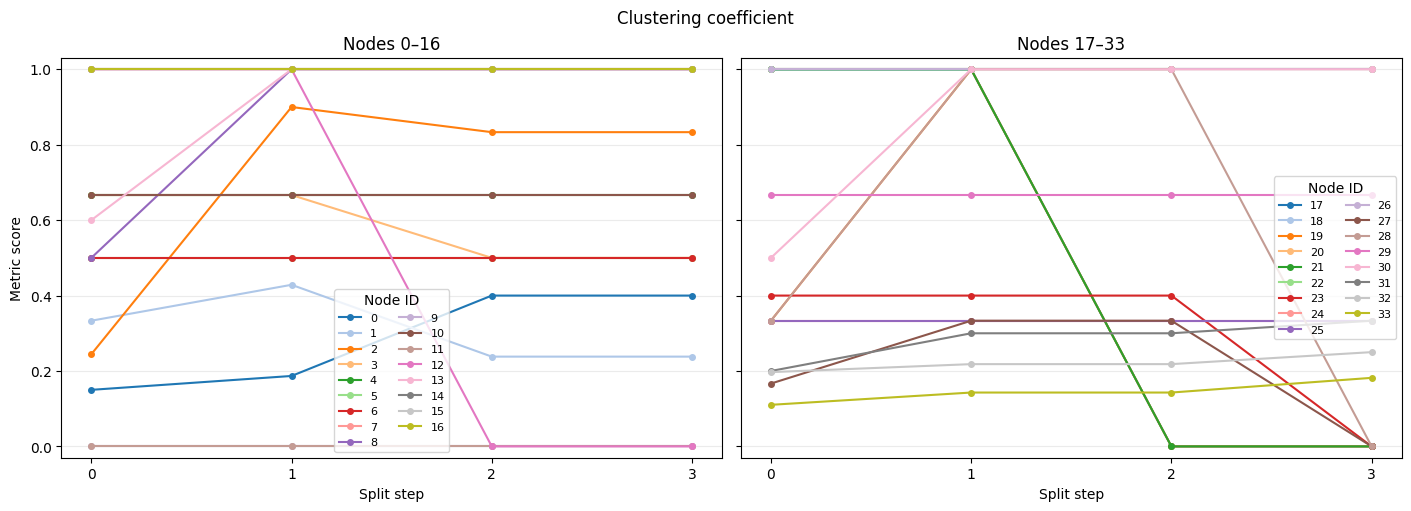

In [55]:
steps = list(metrics)

# Show half the nodes in each panel to keep the legends readable.
midpoint = len(nodes) // 2
node_panels = [nodes[:midpoint], nodes[midpoint:]]

for metric_name in measures:
    fig, axes = plt.subplots(
        1, 2, figsize=(14, 5), sharey=True, layout="constrained"
    )
    fig.suptitle(metric_name)

    for ax, panel_nodes in zip(axes, node_panels):
        for index, node in enumerate(panel_nodes):
            scores = [
                metrics[step][metric_name][node]
                for step in steps
            ]

            ax.plot(
                steps,
                scores,
                color=plt.cm.tab20(index),
                linestyle="-" ,
                marker="o",
                markersize=4,
                label=str(node),
            )

        ax.set_title(f"Nodes {panel_nodes[0]}–{panel_nodes[-1]}")
        ax.set_xlabel("Split step")
        ax.set_xticks(steps)
        ax.set_ylim(-0.03, 1.03)
        ax.grid(axis="y", alpha=0.25)
        ax.legend(title="Node ID", ncol=2, fontsize=8)

    axes[0].set_ylabel("Metric score")
    plt.show()

## 9. Which nodes stay central?
For each centrality measure, I take the five highest-scoring nodes at every step (including ties) and keep the nodes that appear in all of them. The second part prints the scores of the two best-known nodes, 0 (Mr. Hi) and 33 (the president), across all steps.

In [56]:
for name in ("Degree centrality", "Betweenness centrality", "Closeness centrality"):
    consistent = set(nodes)

    for step in steps:
        values = metrics[step][name]
        cutoff = sorted(values.values(), reverse=True)[4]
        leaders = {node for node, value in values.items() if value >= cutoff - TOL}
        consistent.intersection_update(leaders)

    print(f"{name} | top five at every step, including ties: {sorted(consistent)}")

for node in (0, 33):
    print(f"\nNode {node}, from step 0 to the final step")
    for name in measures:
        scores = [round(metrics[step][name][node], 3) for step in steps]
        print(f"  {name}: {scores}")

Degree centrality | top five at every step, including ties: [0, 1, 33]
Betweenness centrality | top five at every step, including ties: [0, 33]
Closeness centrality | top five at every step, including ties: [0, 33]

Node 0, from step 0 to the final step
  Degree centrality: [0.485, 0.933, 0.833, 0.833]
  Betweenness centrality: [0.438, 0.69, 0.378, 0.378]
  Closeness centrality: [0.569, 0.938, 0.857, 0.857]
  Clustering coefficient: [0.15, 0.187, 0.4, 0.4]

Node 33, from step 0 to the final step
  Degree centrality: [0.515, 0.882, 0.882, 1.0]
  Betweenness centrality: [0.304, 0.57, 0.57, 0.564]
  Closeness centrality: [0.55, 0.895, 0.895, 1.0]
  Clustering coefficient: [0.11, 0.143, 0.143, 0.182]


## 10. Animation of the splits
This cell makes a short mp4 of the steps. It needs `imageio-ffmpeg`; if that is not installed the rest of the notebook still runs.

In [57]:
import networkx as nx
import matplotlib.pyplot as plt
import imageio_ffmpeg

from matplotlib.animation import FFMpegWriter
from IPython.display import Video, display

# Scores for the partitions already found by your algorithm.
q_values = [float(modularity(partition)) for partition in history]
q_values = [0.0 if abs(q) < 1e-10 else q for q in q_values]

# Keep nodes in the same positions throughout the video.
positions = nx.spring_layout(
    G, seed=212, weight=None, k=0.5, iterations=200
)

# Assign persistent colors to communities.
colors = {}
palette = plt.get_cmap("tab10").colors

for partition in history:
    for group in partition:
        key = frozenset(group)
        if key not in colors:
            colors[key] = palette[len(colors) % len(palette)]

fig = plt.figure(figsize=(13, 7))
grid = fig.add_gridspec(2, 2, width_ratios=[2, 1])

graph_ax = fig.add_subplot(grid[:, 0])
info_ax = fig.add_subplot(grid[0, 1])
score_ax = fig.add_subplot(grid[1, 1])

fig.subplots_adjust(wspace=0.25, hspace=0.4, bottom=0.12)


def draw_frame(step):
    graph_ax.clear()
    info_ax.clear()
    score_ax.clear()

    partition = history[step]
    gain = q_values[step] - q_values[step - 1] if step > 0 else 0.0

    membership = {}
    for group_number, group in enumerate(partition):
        for node in group:
            membership[node] = group_number

    inside_edges = []
    between_edges = []

    for u, v in G.edges():
        if membership[u] == membership[v]:
            inside_edges.append((u, v))
        else:
            between_edges.append((u, v))

    nx.draw_networkx_edges(
        G, positions, edgelist=between_edges,
        edge_color="#aaaaaa", style="dashed",
        width=1, alpha=0.3, ax=graph_ax,
    )
    nx.draw_networkx_edges(
        G, positions, edgelist=inside_edges,
        edge_color="#555555", width=1.5,
        alpha=0.65, ax=graph_ax,
    )

    for group in partition:
        nx.draw_networkx_nodes(
            G, positions, nodelist=group,
            node_color=[colors[frozenset(group)]],
            node_size=450, edgecolors="white",
            linewidths=1.5, ax=graph_ax,
        )

    nx.draw_networkx_labels(
        G, positions, font_size=9,
        font_color="white", font_weight="bold", ax=graph_ax,
    )

    graph_ax.set_title(f"Karate Club — step {step}", fontsize=16)
    graph_ax.margins(0.12)
    graph_ax.set_axis_off()

    info_ax.set_axis_off()
    info_ax.text(
        0, 0.97,
        f"Communities     {len(partition)}\n"
        f"Modularity Q   {q_values[step]:.6f}\n"
        f"Gain ΔQ        {gain:+.6f}",
        transform=info_ax.transAxes,
        va="top", fontsize=12, linespacing=1.8,
    )

    for index, group in enumerate(partition):
        info_ax.text(
            0, 0.50 - index * 0.10,
            f"●  {len(group)} members",
            color=colors[frozenset(group)],
            transform=info_ax.transAxes,
            fontsize=12, fontweight="bold",
        )

    score_ax.plot(
        range(step + 1), q_values[:step + 1],
        color="#2563eb", marker="o", linewidth=2,
    )
    score_ax.set_xlim(-0.15, max(1, len(history) - 1) + 0.15)
    score_ax.set_ylim(-0.02, max(0.1, max(q_values)) + 0.05)
    score_ax.set_xticks(range(len(history)))
    score_ax.set_xlabel("Accepted split step")
    score_ax.set_ylabel("Modularity Q")
    score_ax.set_title("Modularity so far")
    score_ax.grid(alpha=0.25)


fig.text(
    0.5, 0.03,
    "Solid edges are within communities. Dashed edges cross communities.",
    ha="center", fontsize=10,
)

video_path = "community_detection.mp4"

with plt.rc_context({
    "animation.ffmpeg_path": imageio_ffmpeg.get_ffmpeg_exe()
}):
    writer = FFMpegWriter(
        fps=1,
        codec="libx264",
        extra_args=["-pix_fmt", "yuv420p", "-movflags", "+faststart"],
    )

    with writer.saving(fig, video_path, dpi=100):
        for step in range(len(history)):
            draw_frame(step)

            # Hold each partition for three seconds.
            for _ in range(3):
                writer.grab_frame()

plt.close(fig)

display(Video(
    filename=video_path,
    embed=True,
    width=1000,
    html_attributes="controls",
))

## 11. Discussion

**Nodes that stay central:** Nodes 0 and 33, the two faction leaders, are in the top five
for degree, betweenness and closeness at every step (node 1 also stays in the top five for
degree). Even on the whole graph they are the top two for degree centrality (0.52 and
0.48) and for betweenness (0.44 and 0.30). After the first split they stay on top inside
their own communities (node 0 has betweenness 0.69 and node 33 has 0.57). In the final
partition node 33 reaches degree and closeness 1.0 in its community. These two nodes are
hubs of the network as a whole and also inside their own groups. Nodes like 32 and 31 are
also high, but mostly inside their own communities. Node 32, for example, has 0.74
closeness after step 1 and 0.85 at the end.

**How community structure changes the metrics :** The values jump up after the first
split, for example node 0 goes from 0.48 to 0.93 in degree centrality and from 0.57 to
0.94 in closeness. I think this is mostly a scale effect. I compute every metric on the
community's own subgraph, and networkx divides by the number of nodes in it, so a node
that is joined to most of a smaller group looks more central. I therefore compare ranks
and patterns across steps more than raw values.

Some nodes change in ways that show the structure:
- **Node 1** has betweenness 0.07 after step 1 but 0.65 after step 2. Once its
  9-node community is separated, node 1 connects most of it together.
- **Node 2** has clustering 0.24 on the whole graph but 0.83 to 0.90 inside its
  community. Its neighbors are tightly connected to each other, and the clustering
  stays hidden until the connections to other groups are removed. Its betweenness falls
  from 0.14 on the whole graph to about 0.01, so it was a bridge only because of those
  cross-community edges.
- **Nodes 24, 25 and 31** change most in the last split, which creates a small community
  of six nodes. Their degree centrality goes from 0.18 to 0.60 for 24 and 25, and
  node 31's betweenness goes from 0.11 to 0.40. In a small group, even nodes with low
  degree look central.
- **Node 9** has degree 2 and stays at the bottom for every measure. It lies on the
  boundary between the two factions but holds no central position.

**Clustering coefficient.** The average clustering coefficient is 0.57 on the whole
graph and 0.68 after the first split. The two groups are more tightly knit than the
network overall, which fits the idea that communities are dense inside. It then goes down
to 0.56 and 0.51 in later steps, so more splitting does not always make groups tighter.
Later splits also separate nodes that were connected to each other.

**Connection to modularity.** In the final partition 26 of the 78 edges run between
communities, so about two thirds of the edges are inside groups. The first split gives
almost all the modularity gain (0.371). The later splits add only 0.0012 and 0.0207, so
the main structure is the two-faction split, and the finer groups are smaller refinements.

**Limitations.** Measuring each community separately removes its links to the rest of the
graph, so a node's bridging role across communities does not show up after the split. The
rise in values is partly an effect of the smaller graphs. A fairer comparison would also
compute the metrics on the whole graph and color the nodes by community.